#### 이진 분류

In [552]:
import torch
import matplotlib.pyplot as plt

#### Step 1. 데이터 생성

In [553]:
N = 20

random0 = torch.randn(int(N/2), 1)
random5 = torch.randn(int(N/2), 1)+5

# data
class1_data = torch.hstack([random0,random5])       # 10행 2열
class2_data = torch.hstack([random5,random0])

# label
class1_label = torch.ones(int(N/2), 1)      # 10행 1열
class2_label = torch.zeros(int(N/2), 1)


x = torch.vstack([class1_data, class2_data])        # 20행 2열
y = torch.vstack([class1_label, class2_label])      # 20행 1열
print(x)
print(y)


tensor([[ 0.3689,  5.3876],
        [-0.2961,  4.8204],
        [-0.7604,  3.4102],
        [ 1.3376,  5.2667],
        [-0.0410,  4.5560],
        [-1.2496,  6.4007],
        [-0.0899,  4.9694],
        [-2.8871,  5.3944],
        [ 0.1262,  6.1956],
        [ 1.6506,  4.3045],
        [ 5.3876,  0.3689],
        [ 4.8204, -0.2961],
        [ 3.4102, -0.7604],
        [ 5.2667,  1.3376],
        [ 4.5560, -0.0410],
        [ 6.4007, -1.2496],
        [ 4.9694, -0.0899],
        [ 5.3944, -2.8871],
        [ 6.1956,  0.1262],
        [ 4.3045,  1.6506]])
tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])


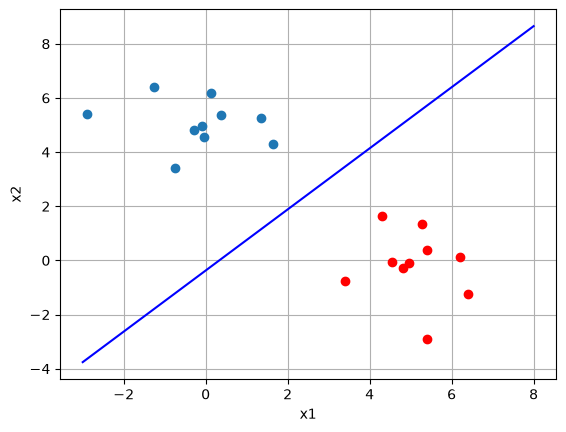

In [559]:

# 1. 기존 데이터 생성 코드 아래에 추가

from torch import nn, optim

# 2. 모델 생성
model = nn.Linear(2, 1)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

# 3. 학습
for epoch in range(1000):
    y_hat = model(x)

    loss = criterion(y_hat, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# 4. 최적의 직선 계산
w1 = model.weight.data[0, 0]
w2 = model.weight.data[0, 1]
b = model.bias.data[0]

x_plot = torch.linspace(-3, 8, 100)
y_plot = -(w1*x_plot + b) / w2

# 5. 그래프
plt.plot(class1_data[:,0], class1_data[:,1], 'o')
plt.plot(class2_data[:,0], class2_data[:,1], 'ro')

plt.plot(x_plot.numpy(), y_plot.numpy(), 'b-')

plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()
plt.show()


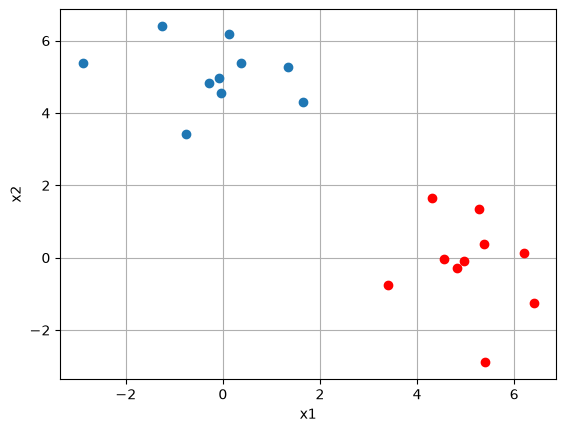

In [554]:
plt.plot(class1_data[:,0], class1_data[:,1],'o')
plt.plot(class2_data[:,0], class2_data[:,1], 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()

#### Step 2. 모델 만들기

In [555]:
from torch import nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(2, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100,1),
                                    nn.Sigmoid()
                                    )
        # self.linear = nn.Sequential(nn.Linear(2, 1),
        #                     nn.Sigmoid()
        #                     )
    def forward(self, x):
        x = self.linear(x)
        return x 

In [556]:
model = MLP()
print(model)

b = model(torch.randn(5,2))
print(b.shape)
print(b)

MLP(
  (linear): Sequential(
    (0): Linear(in_features=2, out_features=100, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=100, out_features=1, bias=True)
    (3): Sigmoid()
  )
)
torch.Size([5, 1])
tensor([[0.4039],
        [0.4319],
        [0.4700],
        [0.4914],
        [0.4623]], grad_fn=<SigmoidBackward0>)


#### Step 3. 모델 학습시키기

In [ ]:
from torch import optim

LR = 1e-1
EPOCH = 100

# optimizer = optim.SGD(model.parameters(), lr = LR)
optimizer = optim.Adam(model.parameters(), lr = LR)

criterion = nn.BCELoss()

loss_history =[]

model.train()        # train mode로 전환
for ep in range(EPOCH):
    # 예측값
    y_hat = model(x)

    # loss 구하기
    loss = criterion(y_hat,y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 출력
    loss_history += [loss.item()]
    print(f'Epoch : {ep+1}, train loss : {loss.item():.4f}')
    print('-'*30)



Epoch : 1, train loss : 0.6115
------------------------------
Epoch : 2, train loss : 0.0789
------------------------------
Epoch : 3, train loss : 0.0145
------------------------------
Epoch : 4, train loss : 0.0033
------------------------------
Epoch : 5, train loss : 0.0008
------------------------------
Epoch : 6, train loss : 0.0002
------------------------------
Epoch : 7, train loss : 0.0001
------------------------------
Epoch : 8, train loss : 0.0000
------------------------------
Epoch : 9, train loss : 0.0000
------------------------------
Epoch : 10, train loss : 0.0000
------------------------------


Text(0, 0.5, 'Loss')

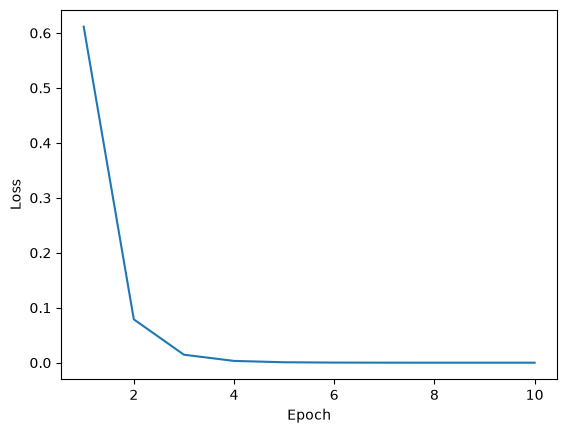

In [558]:
plt.plot(range(1,EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')